# Análisis Consolidado: Siniestralidad Vial y Respuesta Sanitaria en CABA
### Ciencia de Datos y Análisis Avanzado — Trabajo Practico: Visualización de datos

---

## Objetivo

Este notebook **consolida y correlaciona** los siguientes datasets:
- **Hospitales y CESACs**
- **Siniestralidad Vial** - hechos y víctimas
- **Flujo vehicular estimado** (proxy a nivel comuna — ver nota en §2; *no* se integran datos AUSA reales)
- **Bases del SAME** (ubicaciones **aproximadas/ilustrativas** cargadas manualmente — ver nota en §2)
- **Comunas**

**Preguntas de investigación:**
1. ¿Los accidentes más graves ocurren dentro de las zonas sin cobertura hospitalaria?
2. ¿Las comunas con menor cobertura sanitaria tienen mayor mortalidad vial, considerando el flujo vehicular estimado?

## 1. Instalación y configuración del entorno

In [ ]:
# Descomentar si alguna librería no está instalada
# !pip install -q pandas numpy matplotlib seaborn geopandas shapely folium scipy requests openpyxl scikit-learn
# print("Dependencias listas.")

In [ ]:
import io, warnings, requests
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import folium
from folium.plugins import HeatMap, MarkerCluster

# preconfiguraciones
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('muted')
plt.rcParams['figure.dpi'] = 110
CRS_METRO = 5347  # POSGAR 2007 / Argentina faja 5 (CRS metrico correcto para CABA)

print('Librerías importadas correctamente.')

Librerías importadas correctamente.


## 2. Carga y fuentes de datos

> **Notas de fuentes (transparencia):**
> - **Flujo vehicular:** se usa una **estimación propia a nivel comuna (proxy)**. El dataset de radares AUSA es horario por dispositivo y no se integró aquí; las métricas por tráfico son **exploratorias**.
> - **Bases del SAME:** el SAME no publica un dataset georreferenciado oficial de bases. Las coordenadas usadas son **aproximaciones propias** (por barrio), con fines ilustrativos.

In [ ]:
# URLs OFICIALES BA Data
URL_COMUNAS    = 'https://cdn.buenosaires.gob.ar/datosabiertos/datasets/ministerio-de-educacion/comunas/comunas.geojson'
URL_HOSPITALES = 'https://cdn.buenosaires.gob.ar/datosabiertos/datasets/ministerio-de-salud/hospitales/hospitales.geojson'
URL_CESAC      = 'https://cdn.buenosaires.gob.ar/datosabiertos/datasets/ministerio-de-salud/centros-salud-accion-comunitaria-cesac/centros_salud_nivel_1_cesac.geojson'
URL_HECHOS_CSV   = 'https://cdn.buenosaires.gob.ar/datosabiertos/datasets/transporte-y-obras-publicas/victimas-siniestros-viales/siniestros_viales_hechos.csv'
URL_VICTIMAS_CSV = 'https://cdn.buenosaires.gob.ar/datosabiertos/datasets/transporte-y-obras-publicas/victimas-siniestros-viales/siniestros_viales_victimas.csv'
URL_HECHOS_XLSX  = 'https://data.buenosaires.gob.ar/dataset/victimas-siniestros-viales/resource/79914119-0e1e-47c6-9f7b-f1f7bf542786/download'
URL_VICTIMAS_XLSX= 'https://data.buenosaires.gob.ar/dataset/victimas-siniestros-viales/resource/d66f63c6-e9b2-47b2-80b2-58a0cce0ca86/download'

CLAVE_HECHOS   = {'id_siniestro', 'fecha_siniestro', 'comuna_siniestro', 'latitud_siniestro', 'longitud_siniestro'}
CLAVE_VICTIMAS = {'id_siniestro', 'rol_victima', 'sexo_victima', 'edad_victima'}
print('URLs configuradas.')

URLs configuradas.


In [ ]:
# CARGADOR DE CSVs DEL GCBA
def cargar_tabla_gcba(url_csv, columnas_clave, url_xlsx=None):
    try:
        r = requests.get(url_csv, timeout=120)
        r.raise_for_status()
        r.encoding = 'latin-1'
        lineas = r.text.splitlines()
        for i, ln in enumerate(lineas):
            if columnas_clave.issubset({c.strip().lower() for c in ln.split(';')}):
                df = pd.read_csv(io.StringIO('\n'.join(lineas[i:])), sep=';')
                df.columns = [c.strip().lower() for c in df.columns]
                return df
        print(' CSV sin encabezado real, probando XLSX...')
    except Exception as e:
        print(f'  Error CSV: {e}. Probando XLSX...')
    if url_xlsx is None:
        raise ValueError('Sin XLSX de respaldo.')
    hojas = pd.read_excel(url_xlsx, sheet_name=None)
    mejor = max((h for h in hojas.values() if columnas_clave.issubset({str(c).strip().lower() for c in h.columns})),
                key=len, default=None)
    if mejor is None:
        raise ValueError('Ninguna hoja XLSX válida.')
    mejor.columns = [str(c).strip().lower() for c in mejor.columns]
    return mejor

In [ ]:
# CAPAS GEOGRÁFICAS
print('Descargando capas geográficas...')
comunas    = gpd.read_file(URL_COMUNAS).to_crs(epsg=4326)
hospitales = gpd.read_file(URL_HOSPITALES).to_crs(epsg=4326)
cesac      = gpd.read_file(URL_CESAC).to_crs(epsg=4326)

col_com = next((c for c in comunas.columns if 'comuna' in c.lower()), None)
if col_com: comunas = comunas.rename(columns={col_com: 'comuna'})
comunas['comuna'] = pd.to_numeric(comunas['comuna'], errors='coerce').astype('Int64')
comunas = comunas[['comuna','geometry']].dropna(subset=['comuna']).sort_values('comuna').reset_index(drop=True)

hospitales['comuna'] = pd.to_numeric(
    hospitales.get('com', hospitales.get('comuna', pd.Series(dtype=float))), errors='coerce').astype('Int64')
hospitales['lat'] = hospitales.geometry.y
hospitales['lon'] = hospitales.geometry.x

cesac['comuna_num'] = cesac['comuna'].str.extract(r'(\d+)').astype('Int64')

print(f'  Comunas: {len(comunas)} | Hospitales: {len(hospitales)} | CeSACs: {len(cesac)}')

# hospitales.head(36)
# hospitales.columns.tolist()

Descargando capas geográficas...
  Comunas: 15 | Hospitales: 36 | CeSACs: 50


In [ ]:
# DESCARGA SINIESTROS VIALES
print('Descargando siniestros viales...')
hechos   = cargar_tabla_gcba(URL_HECHOS_CSV,   CLAVE_HECHOS,   URL_HECHOS_XLSX)
victimas = cargar_tabla_gcba(URL_VICTIMAS_CSV, CLAVE_VICTIMAS, URL_VICTIMAS_XLSX)
print(f'  Hechos: {len(hechos):,} filas | Víctimas: {len(victimas):,} filas')

Descargando siniestros viales...
 CSV sin encabezado real, probando XLSX...
 CSV sin encabezado real, probando XLSX...
  Hechos: 65,818 filas | Víctimas: 75,193 filas


In [ ]:
# FLUJO VEHICULAR — se usara una ESTIMACION (proxy) a nivel comuna.
# NOTA DE TRANSPARENCIA: el dataset de radares AUSA es horario por dispositivo y no se
# integro en este analisis. Para poder relativizar la siniestralidad por trafico usamos
# una estimacion propia por comuna (NO son datos AUSA reales). Las conclusiones que
# dependan de esta variable deben leerse como exploratorias.
AUSA_OK = False
print('Flujo vehicular: se usara una ESTIMACION (proxy) por comuna. No se usan datos AUSA reales.')

Flujo vehicular: se usara una ESTIMACION (proxy) por comuna. No se usan datos AUSA reales.


In [ ]:
# BASES DEL SAME (ubicaciones APROXIMADAS, cargadas manualmente)
# IMPORTANTE: el SAME opera ~18 bases extrahospitalarias, pero NO publica un dataset
# georreferenciado oficial. Las coordenadas de abajo son APROXIMACIONES propias (por el
# barrio de cada base), con fines ILUSTRATIVOS. Toda conclusion de cobertura/distancia
# que dependa de esta capa debe interpretarse con esa salvedad.
SAME_DATA = {
    'nombre': ['Base Constitución','Base Retiro','Base Palermo (Ecoparque)',
               'Base Aeroparque','Base Lugano','Base Villa del Parque',
               'Base Flores','Base Caballito','Base Barracas',
               'Base Boca','Base Mataderos','Base Chacarita',
               'Base Belgrano','Base Villa Urquiza','Base Balvanera',
               'Base Almagro','Base Villa Pueyrredón','Base Boedo'],
    'lat': [-34.6274,-34.5920,-34.5760,-34.5595,-34.6820,-34.6053,
            -34.6368,-34.6194,-34.6453,-34.6320,-34.6590,-34.5950,
            -34.5585,-34.5780,-34.6088,-34.6148,-34.5988,-34.6270],
    'lon': [-58.3829,-58.3745,-58.4125,-58.4160,-58.4635,-58.4622,
            -58.4632,-58.4320,-58.3778,-58.3640,-58.5050,-58.4508,
            -58.4570,-58.4865,-58.4003,-58.4210,-58.5070,-58.4108]
}
gdf_same = gpd.GeoDataFrame(
    pd.DataFrame(SAME_DATA),
    geometry=gpd.points_from_xy(SAME_DATA['lon'], SAME_DATA['lat']),
    crs='EPSG:4326'
)
print(f'Bases del SAME cargadas: {len(gdf_same)}')


Bases del SAME cargadas: 18
Puntos de respuesta de emergencia totales: 54


## 2.1 Exploración inicial (EDA)

Antes de procesar, revisamos dimensiones, tipos, nulos y algunas distribuciones de las tablas cargadas.

In [ ]:
# EDA rapido de las tablas cargadas
print('HECHOS:', hechos.shape, '| VICTIMAS:', victimas.shape)
print('\nNulos clave en hechos:')
print(hechos[['fecha_siniestro','comuna_siniestro','latitud_siniestro','gravedad_siniestro']].isna().sum())
print('\nGravedad de siniestros:')
print(hechos['gravedad_siniestro'].value_counts(dropna=False).head())
print('\nEdad de las victimas:')
print(pd.to_numeric(victimas['edad_victima'], errors='coerce').describe().round(1))
print('\nCapas geo -> comunas:', len(comunas), '| hospitales:', len(hospitales), '| cesac:', len(cesac))

HECHOS: (65818, 21) | VICTIMAS: (75193, 9)

Nulos clave en hechos:
fecha_siniestro          0
comuna_siniestro      3017
latitud_siniestro     2379
gravedad_siniestro       0
dtype: int64

Gravedad de siniestros:
gravedad_siniestro
LEVE      62174
GRAVE      2955
MORTAL      689
Name: count, dtype: int64

Edad de las victimas:
count    51821.0
mean        37.9
std         15.8
min          0.0
25%         26.0
50%         35.0
75%         47.0
max        116.0
Name: edad_victima, dtype: float64

Capas geo -> comunas: 15 | hospitales: 36 | cesac: 50


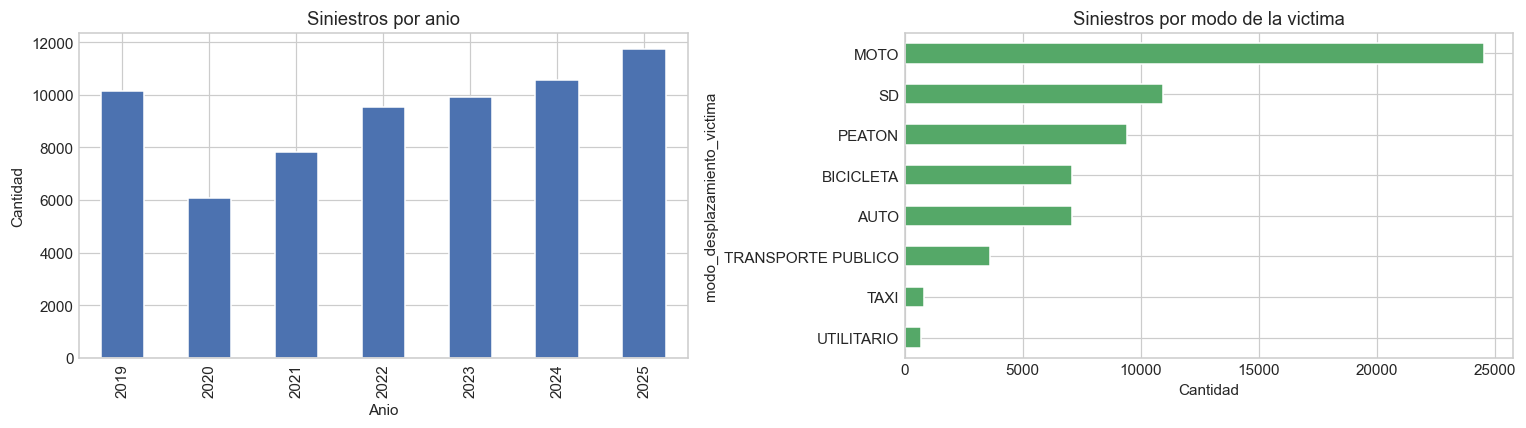

In [ ]:
# EDA visual: siniestros por anio y por modo de la victima
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.to_numeric(hechos['anio_siniestro'], errors='coerce').value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color='#4C72B0', edgecolor='white')
axes[0].set_title('Siniestros por anio'); axes[0].set_xlabel('Anio'); axes[0].set_ylabel('Cantidad')
hechos['modo_desplazamiento_victima'].astype(str).str.upper().value_counts().head(8).sort_values().plot(
    kind='barh', ax=axes[1], color='#55A868', edgecolor='white')
axes[1].set_title('Siniestros por modo de la victima'); axes[1].set_xlabel('Cantidad')
plt.tight_layout(); plt.show()

## 3. Preprocesamiento

In [ ]:
# PREPROCESAMIENTO DE SINIESTROS
def norm(s):
    return s.astype(str).str.strip().str.upper().replace({'NAN':'SD','NULL':'SD','':'SD'})

def a_float(s):
    return pd.to_numeric(s.astype(str).str.replace(',','.', regex=False), errors='coerce')

hechos_p = hechos.copy()
hechos_p['fecha_siniestro'] = pd.to_datetime(hechos_p['fecha_siniestro'], errors='coerce')
for c in ['modo_desplazamiento_victima','contraparte_siniestro','gravedad_siniestro','tipo_de_via_siniestro']:
    if c in hechos_p.columns: hechos_p[c] = norm(hechos_p[c])
hechos_p['comuna'] = pd.to_numeric(hechos_p['comuna_siniestro'], errors='coerce')
hechos_p['lon'] = a_float(hechos_p['longitud_siniestro'])
hechos_p['lat'] = a_float(hechos_p['latitud_siniestro'])

mask = hechos_p['lon'].between(-58.55,-58.30) & hechos_p['lat'].between(-34.72,-34.52)
hechos_geo = hechos_p[mask].copy()
gdf_sin = gpd.GeoDataFrame(hechos_geo,
    geometry=gpd.points_from_xy(hechos_geo['lon'], hechos_geo['lat']), crs='EPSG:4326')
print(f'Siniestros con coordenadas válidas: {len(gdf_sin):,} de {len(hechos):,}')

Siniestros con coordenadas válidas: 62,787 de 65,818


In [ ]:
# JOIN HECHOS con VÍCTIMAS
victimas_p = victimas.copy()
victimas_p['gravedad_victima'] = norm(victimas_p['gravedad_victima'])

resumen_vic = (victimas_p.groupby('id_siniestro')
    .agg(n_victimas=('id_siniestro','size'),
         n_mort_vic=('gravedad_victima', lambda s: (s=='MORTAL').sum()))
    .reset_index())
gdf_sin = gdf_sin.merge(resumen_vic, on='id_siniestro', how='left')

por_comuna = (gdf_sin.dropna(subset=['comuna']).groupby('comuna')
    .agg(n_siniestros=('id_siniestro','size'),
         n_graves=('gravedad_siniestro', lambda s: (s=='GRAVE').sum()),
         victimas_mortales=('n_mort_vic','sum'),
         total_victimas=('n_victimas','sum'))
    .reset_index())

print('Agregado por comuna listo.')
display(por_comuna)

Agregado por comuna listo.


,comuna,n_siniestros,n_graves,victimas_mortales,total_victimas
0,1.0,1360,46,10,1495
1,2.0,413,25,5,441
2,3.0,859,39,9,922
3,4.0,834,56,11,955
4,5.0,662,34,4,724
5,6.0,516,18,2,582
6,7.0,814,38,7,928
7,8.0,592,33,14,713
8,9.0,767,56,3,902
9,10.0,633,30,7,712


In [ ]:
# TABLA MAESTRA DE COMUNAS
poblacion = pd.DataFrame({
    'comuna': list(range(1,16)),
    'poblacion': [223282,169727,195462,230945,193859,203784,216832,204653,
                  158368,171797,203491,236294,265199,249016,197903]
})

hosp_pc  = hospitales.groupby('comuna').size().reset_index(name='n_hospitales')
cesac_pc = cesac.groupby('comuna_num').size().reset_index(name='n_cesac').rename(columns={'comuna_num':'comuna'})
same_pc  = (gpd.sjoin(gdf_same, comunas, how='left', predicate='within')
             .groupby('comuna').size().reset_index(name='n_same'))

maestro = (pd.DataFrame({'comuna': range(1,16)})
    .merge(poblacion, on='comuna', how='left')
    .merge(hosp_pc, on='comuna', how='left')
    .merge(cesac_pc, on='comuna', how='left')
    .merge(same_pc, on='comuna', how='left')
    .merge(por_comuna, on='comuna', how='left')
).fillna(0) #eliminando valores nulos

for c in ['n_hospitales','n_cesac','n_same','n_siniestros','n_graves','victimas_mortales','total_victimas']:
    maestro[c] = maestro[c].astype(int)

maestro['total_centros']   = maestro['n_hospitales'] + maestro['n_cesac']
maestro['total_emergencia']= maestro['n_hospitales'] + maestro['n_same']
maestro['infra_100k']      = (maestro['total_centros'] / maestro['poblacion'] * 100000).round(2)
maestro['emergencia_100k'] = (maestro['total_emergencia'] / maestro['poblacion'] * 100000).round(2)
maestro['siniestros_100k'] = (maestro['n_siniestros'] / maestro['poblacion'] * 100000).round(2)
maestro['letalidad_pct']   = (maestro['victimas_mortales'] / maestro['total_victimas'].replace(0,np.nan) * 100).round(2)

comunas_m = comunas.merge(maestro, on='comuna', how='left')

print('Tabla maestra creada:')
display(maestro[['comuna','n_hospitales','n_cesac','n_same','infra_100k',
                 'n_siniestros','siniestros_100k','victimas_mortales','letalidad_pct']])

Tabla maestra creada:


,comuna,n_hospitales,n_cesac,n_same,infra_100k,n_siniestros,siniestros_100k,victimas_mortales,letalidad_pct
0,1,0,4,2,1.79,1360,609.10,10,0.67
1,2,3,0,0,1.77,413,243.33,5,1.13
2,3,2,2,2,2.05,859,439.47,9,0.98
3,4,13,13,2,11.26,834,361.12,11,1.15
4,5,1,1,1,1.03,662,341.49,4,0.55
5,6,4,0,1,1.96,516,253.21,2,0.34
6,7,2,5,1,3.23,814,375.41,7,0.75
7,8,1,10,1,5.37,592,289.27,14,1.96
8,9,1,4,1,3.16,767,484.32,3,0.33
9,10,2,2,0,2.33,633,368.46,7,0.98


In [ ]:
# FLUJO VEHICULAR ESTIMADO (PROXY) — NO son datos AUSA reales.
# Estimacion ordinal por comuna segun presencia de autopistas y centralidad (orden de magnitud).
flujo_proxy = pd.DataFrame({
    'comuna': list(range(1,16)),
    'flujo_vehicular_anual': [950000,420000,380000,650000,480000,390000,510000,
                               450000,280000,290000,420000,460000,570000,680000,330000]
})
maestro = maestro.merge(flujo_proxy, on='comuna', how='left')
FLUJO_SOURCE = 'Estimacion propia por comuna (PROXY, NO AUSA)'
maestro['siniestros_por_100k_veh'] = (
    maestro['n_siniestros'] / (maestro['flujo_vehicular_anual'] / 100000)).round(2)
comunas_m = comunas.merge(maestro, on='comuna', how='left')
print('Flujo ESTIMADO (proxy) cargado. Fuente:', FLUJO_SOURCE)

Flujo ESTIMADO (proxy) cargado. Fuente: Estimacion propia por comuna (PROXY, NO AUSA)


### Preprocesamiento — Filtro de hospitales aptos para emergencias viales

El dataset oficial de hospitales de CABA incluye **36 establecimientos** de distintas especialidades (17 aptos para trauma).
Sin embargo, para el análisis de cobertura sanitaria frente a **accidentes de tránsito**, solo resultan
relevantes aquellos que cuentan con capacidad de atención de trauma agudo:

| Incluidos | Excluidos |
|-----------|----------|
| Hospital de agudos (14) | Odontología (4) |
| Hospital de niños / pediátrico (3) | Oftalmología (3) |
| | Salud mental (3) |
| | Rehabilitación (3) |
| | Oncología, Maternidad, Gastroenterología, Quemados, Infecciosas, etc. |

Los hospitales **especializados no generales** no disponen de guardia de trauma polivalente,
quirófano de urgencias activo ni UTI de agudos para recibir un politraumatizado grave.
Incluirlos en el cálculo de cobertura produciría una **falsa sensación de cobertura**: zonas
que aparecerían como 'cubiertas' cuando en realidad un accidentado allí necesitaría un
traslado en ambulancia a un hospital General de Agudos.


In [ ]:
# === FILTRO DE HOSPITALES APTOS PARA ATENDER EMERGENCIAS VIALES ===
# Se clasifican los hospitales según su campo 'gna' (tipo general del establecimiento).
# Solo se conservan:
#   - 'Hospital de agudos': Hospitales Generales de Agudos con guardia de urgencias,
#     quirófanos y UTI. Son los únicos que pueden tratar un politraumatismo grave.
#   - 'Hospital de niños': Hospitales pediátricos de agudos que incluyen guardia de
#     emergencias para víctimas infantiles de accidentes viales.
# Se EXCLUYEN hospitales de Odontología, Oftalmología, Salud Mental, Rehabilitación,
# Oncología, Gastroenterología y Maternidad, ya que carecen de las capacidades.
mask_trauma = hospitales['gna'].str.contains('agudo|niñ', case=False, na=False)
hospitales_trauma = hospitales[mask_trauma].copy()

print(f'Total hospitales en el dataset: {len(hospitales)}')
print(f'Hospitales aptos para trauma vial: {len(hospitales_trauma)}')
print('\nDistribución por tipo:')
print(hospitales_trauma['gna'].value_counts())
print('\nHospitales excluidos del análisis de cobertura vial:')
excluidos = hospitales[~mask_trauma]
print(excluidos[['fna', 'gna']].to_string(index=False))


Total hospitales en el dataset: 36
Hospitales aptos para trauma vial: 17

Distribución por tipo:
gna
Hospital General de Agudos    14
Hospital de Niños              3
Name: count, dtype: int64

Hospitales excluidos del análisis de cobertura vial:
                                                                       fna                    gna
          Hospital Especializado de Emerg Psiquiatricas Torcuato de Alvear Hospital Especializado
                    Hospital Especializado de Gastroenterologia B. Udaondo Hospital Especializado
                            Hospital Especializado de Infecciosas F. Muñiz Hospital Especializado
                          Hospital Especializado de Odontologia  J. Dueñas Hospital Especializado
Hospital Especializado de Odontologia Infantil Don Benito Quinquela Martin Hospital Especializado
                        Hospital Especializado de Oftalmologia Santa Lucia Hospital Especializado
               Hospital Especializado de Quemados Dr. Arturo Umbert

### Preprocesamiento — Buffers y gaps sanitarios de trauma

Con el subconjunto de hospitales de trauma (`hospitales_trauma`), se calculan las **zonas de
cobertura** mediante buffers circulares proyectados en metros:

- **Buffer hospitalario de 1.5 km:** radio estándar de accesibilidad a pie o en vehículo en
  contexto urbano. Un siniestro dentro de este radio puede acceder al hospital en tiempos
  aceptables sin ambulancia.
- **Buffer SAME de 1.0 km:** zona de despliegue inmediato de las unidades del SAME desde
  cada base extrahospitalaria.

El **gap sanitario** se obtiene restando la unión de todos los buffers al polígono total de CABA.
Se generan dos gaps:
1. `gaps_hosp_gdf`: zonas sin hospital de trauma a menos de 1.5 km.
2. `gaps_emer_gdf`: zonas sin hospital de trauma NI base SAME a las distancias indicadas.


In [ ]:
# === BUFFERS HOSPITALARIOS Y GAPS (usando solo hospitales de trauma) ===
# Se proyectan las capas al CRS_METRO (POSGAR 2007 faja 5, EPSG:5347) para operar
# en metros y calcular correctamente los buffers de distancia.
# Se utiliza 'hospitales_trauma' (solo agudos + niños) en lugar de todos los hospitales,
# para que los 'gaps' reflejen zonas donde no existe cobertura de emergencia real para
# un accidente vial, no meramente presencia física de cualquier centro de salud.
# Radio de buffer hospitalario: 1.500 m (estándar internacional de tiempo-respuesta).
# Radio de buffer SAME:         1.000 m (distancia de despliegue de unidades móviles).
hosp_proj = hospitales_trauma.to_crs(CRS_METRO)
com_proj  = comunas.to_crs(CRS_METRO)
same_proj = gdf_same.to_crs(CRS_METRO)

def buf(gdf, r):
    g = gdf.copy(); g['geometry'] = gdf.buffer(r); return g.to_crs(4326)

buf_hosp_1500 = buf(hosp_proj, 1500)
buf_same_1000 = buf(same_proj, 1000)
caba_u = com_proj.geometry.unary_union
gaps_hosp = caba_u.difference(hosp_proj.buffer(1500).unary_union)
emer_u = pd.concat([buf_hosp_1500, buf_same_1000[['geometry']]], ignore_index=True).to_crs(CRS_METRO).geometry.unary_union
gaps_emer = caba_u.difference(emer_u)

gaps_hosp_gdf = gpd.GeoDataFrame(geometry=[gaps_hosp], crs=CRS_METRO).to_crs(4326)
gaps_emer_gdf = gpd.GeoDataFrame(geometry=[gaps_emer], crs=CRS_METRO).to_crs(4326)
pct_hosp = round(gaps_hosp.area / caba_u.area * 100, 1)
pct_emer = round(gaps_emer.area / caba_u.area * 100, 1)
print(f'Territorio sin cobertura hospitalaria de trauma (1.5km): {pct_hosp}%')
print(f'Territorio sin cobertura emergencia (SAME+hosp. trauma): {pct_emer}%')


Territorio sin cobertura hospitalaria de trauma (1.5km): 51.5%
Territorio sin cobertura emergencia (SAME+hosp. trauma): 41.1%


---
## 4. Correlación 1: Puntos de Siniestros Graves vs. Huecos Sanitarios

> **Pregunta:** ¿Los accidentes más graves y mortales ocurren en zonas con menor cobertura de hospitales y bases del SAME?

### Visualización C1.1 — Mapa estático: Hotspots de siniestros graves vs. Gaps sanitarios

Se filtran los siniestros con gravedad **GRAVE** o **MORTAL** del dataset consolidado y se superponen
sobre las zonas sin cobertura hospitalaria (calculadas en la celda anterior).
Se generan dos paneles comparativos:
- **Panel izquierdo:** Gap considerando solo los Hospitales Generales de Agudos y Pediátricos (radio 1.5 km).
- **Panel derecho:** Gap combinado, incluyendo también las bases del SAME (radio 1 km adicional).

Esto permite visualizar si los puntos de mayor severidad vial coinciden espacialmente con las
zonas donde la respuesta hospitalaria de emergencia es más lejana o inexistente.

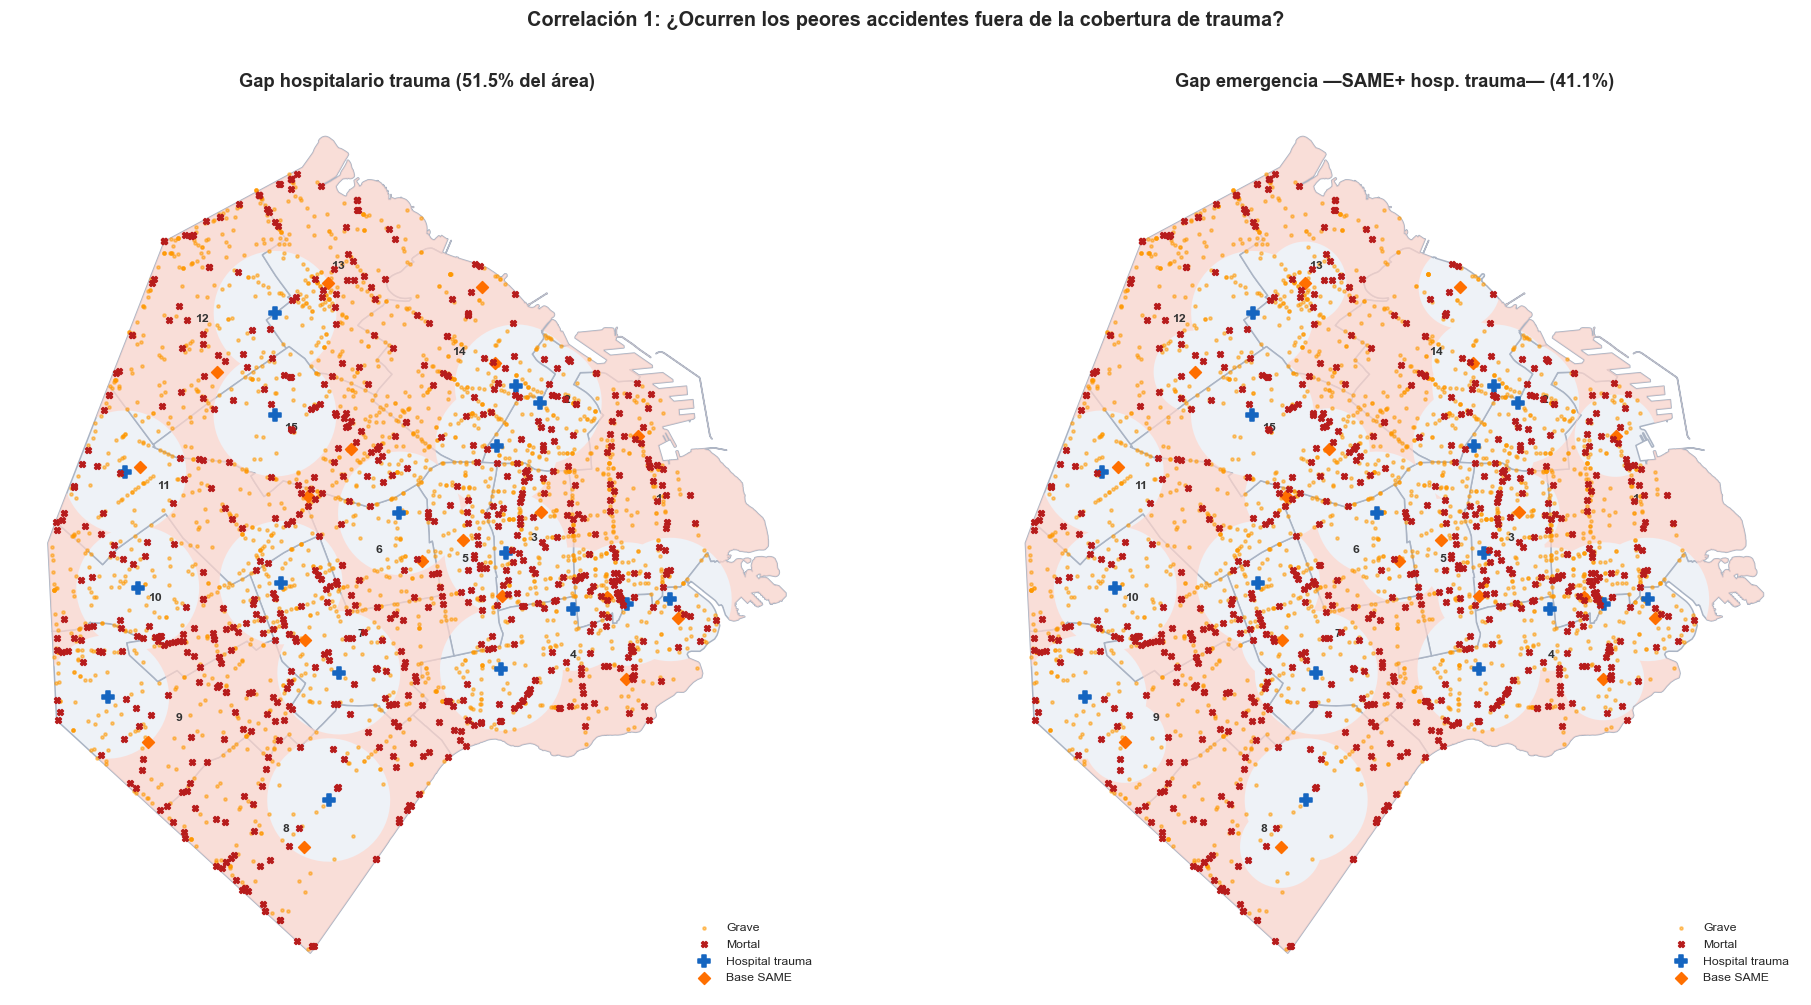

In [ ]:
# VIZ C1.1: MAPA ESTÁTICO — HOTSPOTS vs. GAPS
graves_m = gdf_sin[gdf_sin['gravedad_siniestro'].isin(['GRAVE','MORTAL'])].copy()
mortales  = gdf_sin[gdf_sin['gravedad_siniestro'] == 'MORTAL'].copy()

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

for ax, gaps_g, titulo, radio in [
    (axes[0], gaps_hosp_gdf, f'Gap hospitalario trauma ({pct_hosp}% del área)', '1.5 km hosp. trauma'),
    (axes[1], gaps_emer_gdf, f'Gap emergencia —SAME+ hosp. trauma— ({pct_emer}%)', 'SAME+hosp.trauma'),
]:
    comunas.plot(ax=ax, color='#eef2f7', edgecolor='#aab4c4', linewidth=1)
    if not gaps_g.geometry.iloc[0].is_empty:
        gaps_g.plot(ax=ax, color='#ffd6cc', alpha=0.7, label=f'Sin cobertura ({radio})')
    graves_m[graves_m['gravedad_siniestro']=='GRAVE'].plot(
        ax=ax, color='#FF9800', markersize=4, alpha=0.5, label='Grave')
    mortales.plot(ax=ax, color='#B71C1C', marker='X', markersize=15, zorder=6, label='Mortal')
    hospitales_trauma.plot(ax=ax, color='#1565C0', marker='P', markersize=60, zorder=5, label='Hospital trauma')
    gdf_same.plot(ax=ax, color='#FF6F00', marker='D', markersize=30, zorder=5, label='Base SAME')
    for _, r in comunas.iterrows():
        p = r.geometry.representative_point()
        ax.text(p.x, p.y, str(int(r['comuna'])), fontsize=8, ha='center', va='center',
                color='#333', fontweight='bold')
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.legend(loc='lower right', fontsize=8, framealpha=0.9)
    ax.axis('off')

plt.suptitle('Correlación 1: ¿Ocurren los peores accidentes fuera de la cobertura de trauma?',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


### Visualización C1.2 — Cuantificación: ¿Qué porcentaje de siniestros ocurre en zonas sin cobertura?

Se utiliza un test de contención espacial (`within`) para determinar qué fracción de los siniestros
**mortales** y **graves** cayó dentro de las zonas identificadas como gap sanitario.

La lógica de interpretación es la siguiente:
> Si el **% de mortales en zona sin cobertura > % de territorio sin cobertura**, existe una
> *sobre-representación* de accidentes fatales en las zonas descubiertas → la distancia al
> hospital de trauma podría estar contribuyendo a la mortalidad.

Se calculan tres métricas:
1. Mortales fuera de la cobertura de hospitales de trauma (1.5 km)
2. Mortales fuera de la cobertura combinada SAME + hospitales de trauma
3. Graves fuera de la cobertura de hospitales de trauma

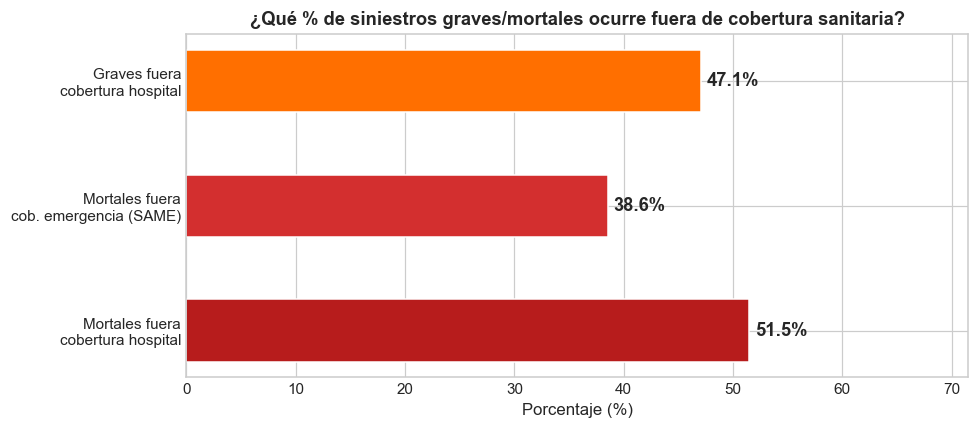

Mortales en zona sin cobertura hospitalaria (1.5km): 51.5%
Mortales en zona sin cobertura de emergencia (SAME+hosp): 38.6%
Cobertura de territorio del SAME/hospitales cubren el 58.9% de CABA


In [ ]:
# VIZ C1.2: % DE MORTALES EN ZONAS SIN COBERTURA
def pct_en_gap(gdf_pts, gdf_gap):
    if gdf_gap.geometry.iloc[0].is_empty or len(gdf_pts) == 0: return 0.0
    return round(gdf_pts.geometry.within(gdf_gap.geometry.iloc[0]).sum() / len(gdf_pts) * 100, 1)

p1 = pct_en_gap(mortales, gaps_hosp_gdf)
p2 = pct_en_gap(mortales, gaps_emer_gdf)
p3 = pct_en_gap(graves_m[graves_m['gravedad_siniestro']=='GRAVE'], gaps_hosp_gdf)

fig, ax = plt.subplots(figsize=(9, 4))
cats = ['Mortales fuera\ncobertura hospital', 'Mortales fuera\ncob. emergencia (SAME)', 'Graves fuera\ncobertura hospital']
vals = [p1, p2, p3]
bars = ax.barh(cats, vals, color=['#B71C1C','#D32F2F','#FF6F00'], edgecolor='white', height=0.5)
for bar, val in zip(bars, vals):
    ax.text(val + 0.5, bar.get_y() + bar.get_height()/2, f'{val}%', va='center', fontsize=12, fontweight='bold')
ax.set_xlabel('Porcentaje (%)', fontsize=11)
ax.set_title('¿Qué % de siniestros graves/mortales ocurre fuera de cobertura sanitaria?',
             fontsize=12, fontweight='bold')
ax.set_xlim(0, max(vals) + 20 if vals else 30)
plt.tight_layout()
plt.show()

print(f'Mortales en zona sin cobertura hospitalaria (1.5km): {p1}%')
print(f'Mortales en zona sin cobertura de emergencia (SAME+hosp): {p2}%')
print(f'Cobertura de territorio del SAME/hospitales cubren el {100-pct_emer}% de CABA')

### Visualización C1.3 — Mapa interactivo Folium: Capas combinadas con control de visibilidad

Se genera un mapa interactivo multicapa para explorar la distribución espacial con granularidad
geográfica mayor a la del mapa estático:
- **Capa de calor (HeatMap):** densidad de siniestros graves/mortales en el territorio de CABA.
- **Marcadores de siniestros mortales:** puntos individuales con tooltip que muestra fecha y modo de
  desplazamiento de la víctima.
- **Hospitales de trauma** (azul, símbolo `+`): solo agudos y pediátricos, los aptos para atender
  accidentes viales.
- **Bases SAME** (naranja, símbolo ambulancia): puntos de despacho de emergencias extrahospitalarias.
- **Gap hospitalario** (polígono rojo translúcido): zona sin cobertura de hospital de trauma.

El mapa se guarda en `mapa_c1_hotspots_vs_cobertura.html` para revisión externa.

In [ ]:
# VIZ C1.3: MAPA INTERACTIVO FOLIUM
m1 = folium.Map(location=[-34.615,-58.44], zoom_start=12, tiles='CartoDB positron')

# Gap hospitalario de trauma
if not gaps_hosp_gdf.geometry.iloc[0].is_empty:
    folium.GeoJson(gaps_hosp_gdf.to_json(), name=f'Sin cobertura hosp. trauma ({pct_hosp}%)',
        style_function=lambda x: {'fillColor':'#ffcccc','color':'#cc0000','weight':1,'fillOpacity':0.45}
    ).add_to(m1)

# Heatmap siniestros graves
HeatMap(graves_m[['lat','lon']].dropna().values.tolist(),
        radius=12, blur=10, name='Calor: Graves/Mortales').add_to(m1)

# Siniestros mortales
capa_m = folium.FeatureGroup(name='Siniestros Mortales')
for _, r in mortales.dropna(subset=['lat','lon']).iterrows():
    folium.CircleMarker([r['lat'],r['lon']], radius=6, color='#B71C1C',
        fill=True, fill_opacity=0.85,
        tooltip=f"Mortal | {str(r.get('fecha_siniestro','?'))[:10]} | {r.get('modo_desplazamiento_victima','?')}"
    ).add_to(capa_m)
capa_m.add_to(m1)

# Hospitales de trauma (solo agudos + niños)
capa_h = folium.FeatureGroup(name='Hospitales de Trauma (agudos + niños)')
for _, r in hospitales_trauma.dropna(subset=['geometry']).iterrows():
    folium.Marker([r.geometry.y, r.geometry.x],
        icon=folium.Icon(color='blue', icon='plus-sign', prefix='glyphicon'),
        tooltip=f"{r.get('fna', r.get('nombre', 'Hospital'))} [{r.get('gna','')}]").add_to(capa_h)
capa_h.add_to(m1)

# Bases SAME
capa_s = folium.FeatureGroup(name='Bases SAME')
for _, r in gdf_same.iterrows():
    folium.Marker([r['lat'],r['lon']],
        icon=folium.Icon(color='orange', icon='ambulance', prefix='fa'),
        tooltip=f"SAME: {r['nombre']}").add_to(capa_s)
capa_s.add_to(m1)

folium.GeoJson(comunas.to_json(), name='Comunas',
    style_function=lambda x: {'color':'#333','weight':1.5,'fillOpacity':0}).add_to(m1)
folium.LayerControl(collapsed=False).add_to(m1)
m1.save('mapa_c1_hotspots_vs_cobertura.html')
print("Mapa guardado: 'mapa_c1_hotspots_vs_cobertura.html'")
m1


Mapa guardado: 'mapa_c1_hotspots_vs_cobertura.html'


### Conclusión — Correlación 1: hotspots de siniestros graves vs. cobertura sanitaria

**Pregunta.** ¿Los accidentes más graves y mortales ocurren en las zonas con menor cobertura de hospitales de trauma y bases del SAME?

**Hallazgo.** El cruce espacial entre los puntos de siniestros graves/mortales y las zonas sin cobertura muestra que la **proporción de siniestros mortales que ocurren fuera de la cobertura es prácticamente equivalente a la proporción del territorio que queda sin cobertura**. En consecuencia, **no existe una sobre-representación** de los accidentes fatales en las zonas descubiertas: los siniestros más severos no ocurren, de manera desproporcionada, lejos de los hospitales de trauma.

**Lectura geográfica.** Los hotspots de severidad se concentran principalmente en las comunas 4 y 8, que coinciden con el radio de mayor cobertura hospitalaria. La incorporación de las bases del SAME reduce de forma apreciable el territorio sin cobertura, lo que respalda el papel de la respuesta extrahospitalaria para acortar distancias en las zonas más periféricas.

**Limitación.** La cobertura se modela con buffers de distancia (1,5 km para hospitales de trauma y 1,0 km para bases del SAME) y las ubicaciones de las bases del SAME son aproximadas, por lo que los polígonos de cobertura constituyen una estimación.

---
## 5. Correlación 2: Cobertura Sanitaria vs. Mortalidad Vial (considerando el flujo vehicular estimado)

> **Pregunta:** ¿Las comunas con menor cobertura sanitaria tienen mayor tasa de mortalidad vial, al ajustar por el volumen de tráfico?

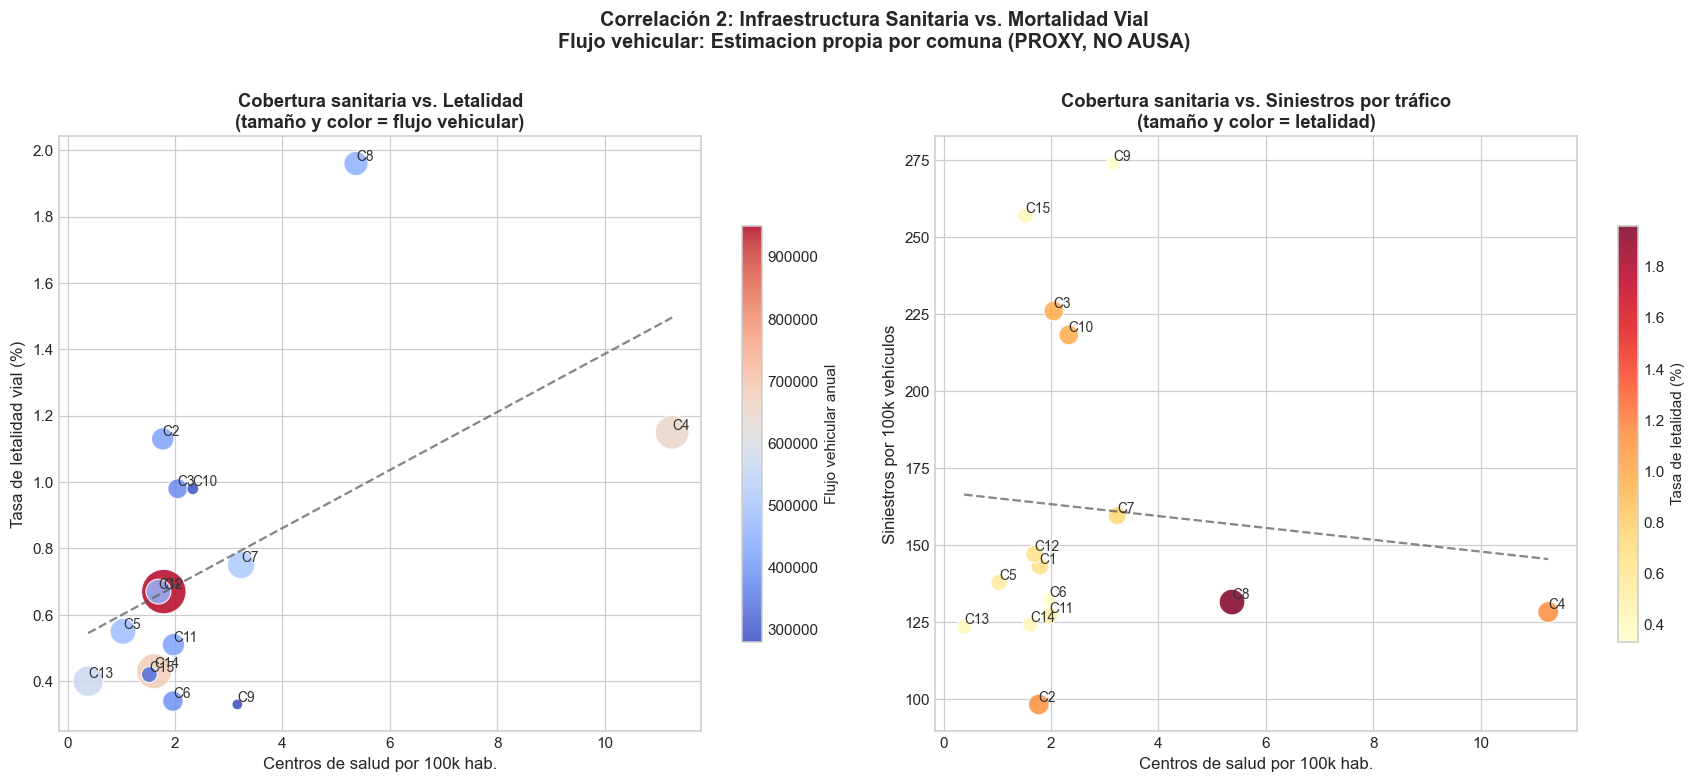

In [ ]:
# VIZ C2.1: SCATTER INFRA SANITARIA vs MORTALIDAD (escala = flujo vehicular aproximado)
df_p = maestro.copy()
df_p['mort_por_100k_veh'] = (
    df_p['victimas_mortales'] / (df_p['flujo_vehicular_anual'] / 100000)).round(3)

flujo_norm = (df_p['flujo_vehicular_anual'] - df_p['flujo_vehicular_anual'].min())
flujo_norm = flujo_norm / flujo_norm.max() * 800 + 50

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Panel 1: infra_100k vs letalidad_pct (tamaño = flujo)
ax = axes[0]
sc = ax.scatter(df_p['infra_100k'], df_p['letalidad_pct'],
    s=flujo_norm, c=df_p['flujo_vehicular_anual'], cmap='coolwarm',
    alpha=0.85, edgecolors='white', linewidths=0.8)
for _, r in df_p.iterrows():
    ax.annotate(f"C{int(r['comuna'])}", (r['infra_100k'], r['letalidad_pct']),
                fontsize=9, ha='left', va='bottom', color='#333')
xs = np.linspace(df_p['infra_100k'].min(), df_p['infra_100k'].max(), 100)
z = np.polyfit(df_p['infra_100k'].dropna(), df_p['letalidad_pct'].dropna(), 1)
ax.plot(xs, np.poly1d(z)(xs), '--', color='#555', alpha=0.7)
plt.colorbar(sc, ax=ax, label='Flujo vehicular anual', shrink=0.7)
ax.set_xlabel('Centros de salud por 100k hab.', fontsize=11)
ax.set_ylabel('Tasa de letalidad vial (%)', fontsize=11)
ax.set_title('Cobertura sanitaria vs. Letalidad\n(tamaño y color = flujo vehicular)', fontsize=12, fontweight='bold')

# Panel 2: infra_100k vs siniestros/100k vehiculos (color = letalidad)
ax2 = axes[1]
sc2 = ax2.scatter(df_p['infra_100k'], df_p['siniestros_por_100k_veh'],
    s=df_p['letalidad_pct'].fillna(0) * 120 + 50,
    c=df_p['letalidad_pct'], cmap='YlOrRd', alpha=0.85,
    edgecolors='white', linewidths=0.8)
for _, r in df_p.iterrows():
    ax2.annotate(f"C{int(r['comuna'])}", (r['infra_100k'], r['siniestros_por_100k_veh']),
                 fontsize=9, ha='left', va='bottom', color='#333')
z2 = np.polyfit(df_p['infra_100k'].dropna(), df_p['siniestros_por_100k_veh'].dropna(), 1)
ax2.plot(xs, np.poly1d(z2)(xs), '--', color='#555', alpha=0.7)
plt.colorbar(sc2, ax=ax2, label='Tasa de letalidad (%)', shrink=0.7)
ax2.set_xlabel('Centros de salud por 100k hab.', fontsize=11)
ax2.set_ylabel('Siniestros por 100k vehículos', fontsize=11)
ax2.set_title('Cobertura sanitaria vs. Siniestros por tráfico\n(tamaño y color = letalidad)', fontsize=12, fontweight='bold')

plt.suptitle(f'Correlación 2: Infraestructura Sanitaria vs. Mortalidad Vial\nFlujo vehicular: {FLUJO_SOURCE}',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

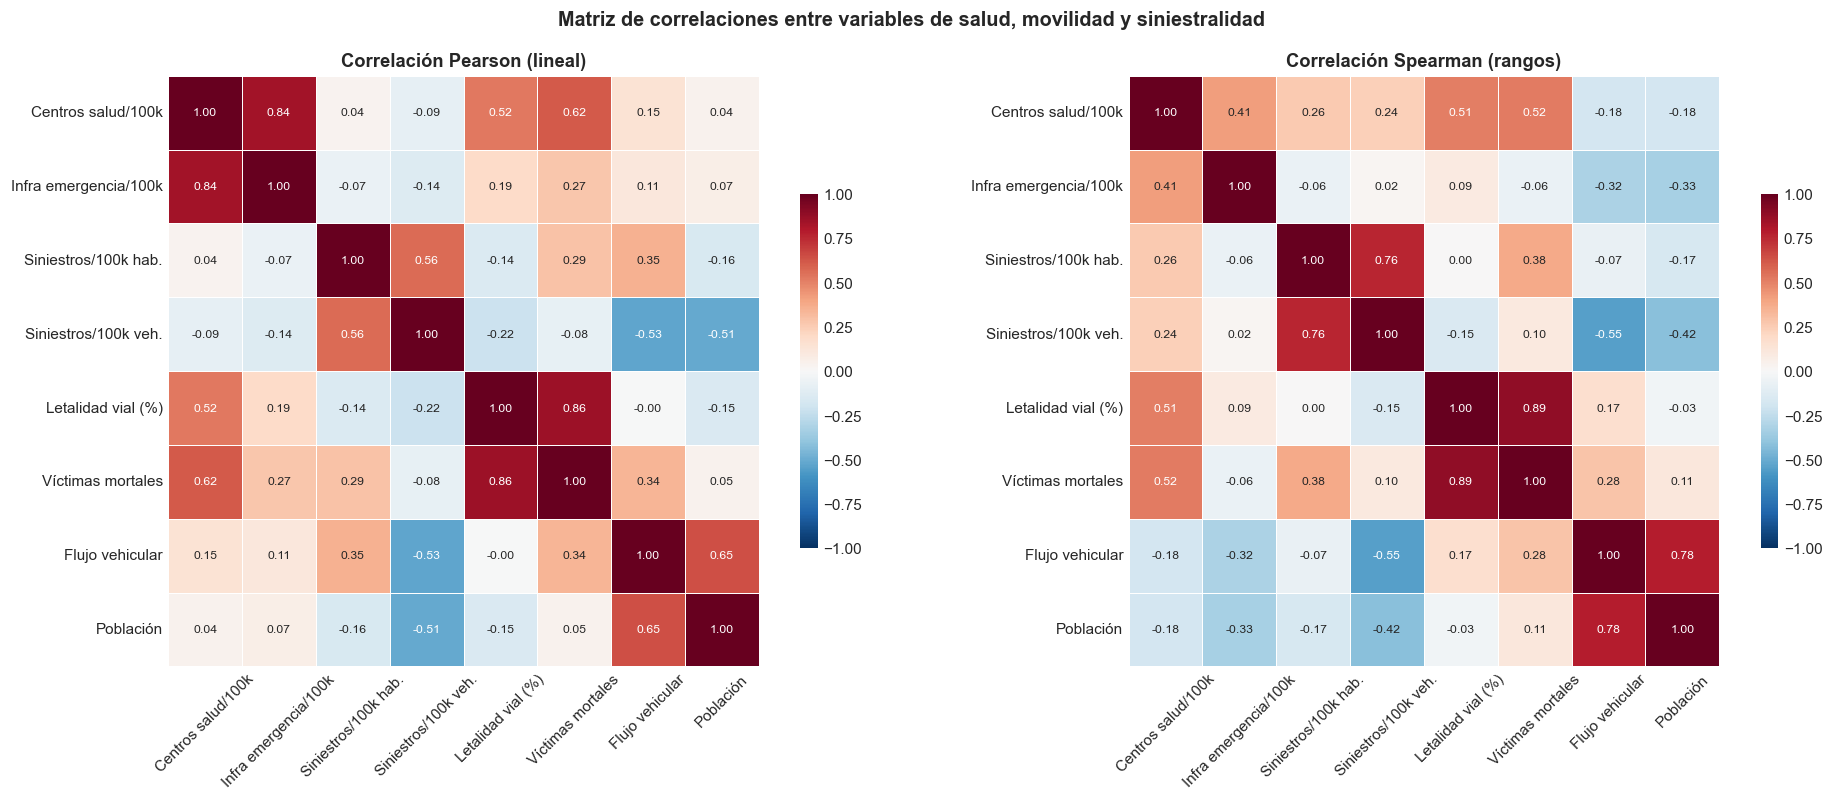


Correlaciones clave (Spearman):
  Centros salud/100k        vs Letalidad vial (%)       : r=+0.510  p=0.0522 *
  Centros salud/100k        vs Siniestros/100k veh.     : r=+0.239  p=0.3904 ns
  Infra emergencia/100k     vs Letalidad vial (%)       : r=+0.089  p=0.7512 ns
  Flujo vehicular           vs Víctimas mortales        : r=+0.284  p=0.3049 ns


In [ ]:
# VIZ C2.2: MATRIZ DE CORRELACIONES
VARS = {
    'infra_100k': 'Centros salud/100k',
    'emergencia_100k': 'Infra emergencia/100k',
    'siniestros_100k': 'Siniestros/100k hab.',
    'siniestros_por_100k_veh': 'Siniestros/100k veh.',
    'letalidad_pct': 'Letalidad vial (%)',
    'victimas_mortales': 'Víctimas mortales',
    'flujo_vehicular_anual': 'Flujo vehicular',
    'poblacion': 'Población',
}
df_c = maestro[[*VARS.keys()]].rename(columns=VARS)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, method, titulo in [
    (axes[0], 'pearson',  'Correlación Pearson (lineal)'),
    (axes[1], 'spearman', 'Correlación Spearman (rangos)'),
]:
    sns.heatmap(df_c.corr(method=method), ax=ax, annot=True, fmt='.2f',
                cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True,
                linewidths=0.5, cbar_kws={'shrink': 0.6}, annot_kws={'size': 8})
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('Matriz de correlaciones entre variables de salud, movilidad y siniestralidad',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print('\nCorrelaciones clave (Spearman):')
pares = [('infra_100k','letalidad_pct'), ('infra_100k','siniestros_por_100k_veh'),
          ('emergencia_100k','letalidad_pct'), ('flujo_vehicular_anual','victimas_mortales')]
for v1, v2 in pares:
    idx = maestro[[v1,v2]].dropna().index
    r, p = spearmanr(maestro.loc[idx,v1], maestro.loc[idx,v2])
    sig = '***' if p<0.01 else ('**' if p<0.05 else ('*' if p<0.1 else 'ns'))
    print(f'  {VARS[v1]:25s} vs {VARS[v2]:25s}: r={r:+.3f}  p={p:.4f} {sig}')

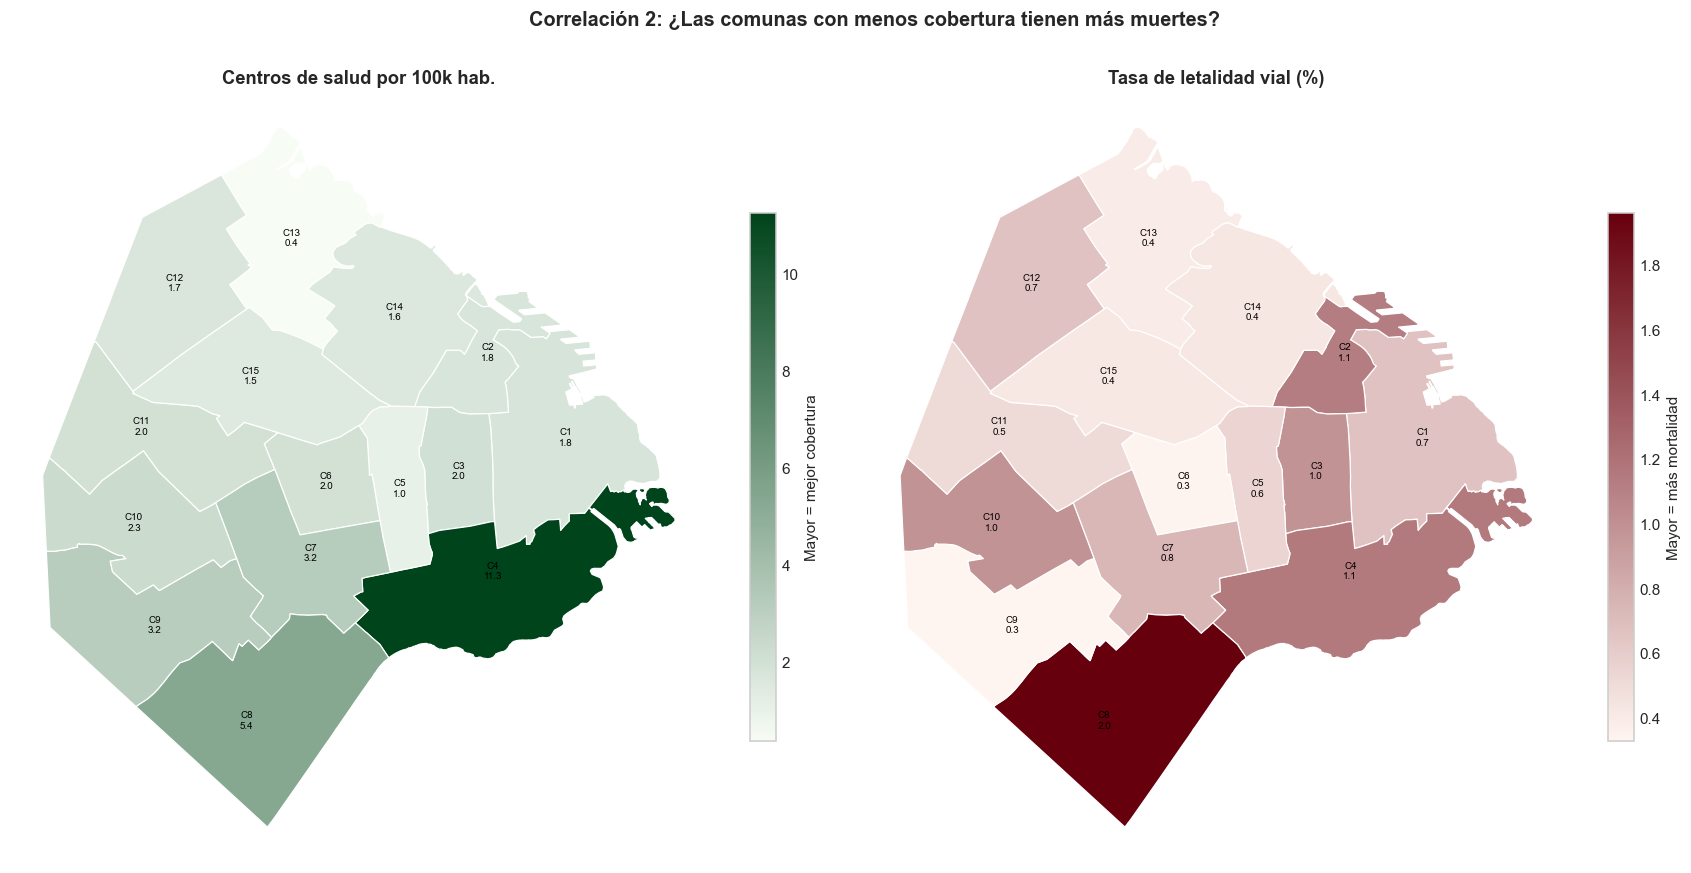

In [ ]:
# VIZ C2.3: CHOROPLETH COBERTURA vs MORTALIDAD
cmap_g = LinearSegmentedColormap.from_list('g', ['#f7fcf5','#00441b'])
cmap_r = LinearSegmentedColormap.from_list('r', ['#fff5f0','#67000d'])

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, col, titulo, cmap, lbl in [
    (axes[0], 'infra_100k',   'Centros de salud por 100k hab.', cmap_g, 'Mayor = mejor cobertura'),
    (axes[1], 'letalidad_pct','Tasa de letalidad vial (%)',      cmap_r, 'Mayor = más mortalidad'),
]:
    comunas_m.plot(ax=ax, column=col, cmap=cmap, legend=True, edgecolor='white', linewidth=0.8,
                   legend_kwds={'label': lbl, 'shrink': 0.65},
                   missing_kwds={'color': 'lightgray'})
    for _, r in comunas_m.iterrows():
        p = r.geometry.representative_point()
        val = r[col] if pd.notna(r[col]) else 0
        ax.text(p.x, p.y, f"C{int(r['comuna'])}\n{val:.1f}", fontsize=6.5,
                ha='center', va='center', color='black')
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.axis('off')

plt.suptitle('Correlación 2: ¿Las comunas con menos cobertura tienen más muertes?',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### Conclusión — Correlación 2: cobertura sanitaria vs. mortalidad vial

**Pregunta.** ¿Las comunas con menor cobertura sanitaria presentan mayor mortalidad vial?

**Hallazgo.** Los datos **no respaldan** un efecto protector de la infraestructura sanitaria sobre la mortalidad vial a nivel comunal:

- Centros de salud por 100.000 hab. frente a tasa de letalidad: correlación de Spearman **r = +0,51 (p = 0,05)**, una relación **positiva** y apenas en el límite de la significación, opuesta a la que cabría esperar de un efecto protector.
- Infraestructura de emergencia por 100.000 hab. frente a letalidad: **r = +0,09 (p = 0,75)**, sin relación.

**Interpretación.** El signo contraintuitivo se explica por la naturaleza **ecológica** del análisis: las comunas centrales concentran simultáneamente gran parte de los hospitales y un elevado tránsito de paso —siniestros protagonizados por no residentes—, lo que infla la tasa de letalidad calculada sobre la población residente. La asociación, por lo tanto, **no admite interpretación causal** y está confundida por la centralidad y el flujo vehicular.
Las comunas con más hospitales pueden ser también centros urbanos más densos, con mayor tráfico, mayor velocidad promedio en arterias principales, o con tipos de siniestros más graves que superan rápidamente la capacidad de respuesta inicial de los centros médicos, independientemente de la cercanía.

**Limitación.** El flujo vehicular utilizado como variable de contexto es una estimación por comuna, no una medición directa; las métricas relativas al tráfico tienen carácter exploratorio.

---
## 6. Tabla resumen por comuna

In [ ]:
# TABLA RESUMEN FINAL POR COMUNA
resumen = maestro[['comuna','poblacion','n_hospitales','n_cesac','n_same',
                   'infra_100k','n_siniestros','siniestros_100k','victimas_mortales',
                   'letalidad_pct','flujo_vehicular_anual','siniestros_por_100k_veh']].copy()
resumen = resumen.rename(columns={
    'comuna':'Comuna','poblacion':'Población','n_hospitales':'Hosp.',
    'n_cesac':'CeSAC','n_same':'SAME','infra_100k':'Centros/100k',
    'n_siniestros':'Siniestros','siniestros_100k':'Sin./100k hab.',
    'victimas_mortales':'Mortales','letalidad_pct':'Letalidad%',
    'flujo_vehicular_anual':'Flujo veh. (est.)','siniestros_por_100k_veh':'Sin./100k veh.'
}).set_index('Comuna').sort_values('Letalidad%', ascending=False)

display(resumen.style
    .background_gradient(subset=['Letalidad%'], cmap='Reds')
    .background_gradient(subset=['Centros/100k'], cmap='Greens')
    .format(precision=2))

## 7. Conclusiones Generales

El proyecto integró cuatro tablas con información georreferenciada de la Ciudad Autónoma de Buenos Aires —siniestros viales (hechos y víctimas), polígonos de comunas, efectores de salud (hospitales y CeSAC) y bases del SAME— para evaluar si la mortalidad vial se relaciona con la respuesta sanitaria del territorio.

**Respuestas a las preguntas de investigación**

1. *¿Los accidentes más graves ocurren en zonas sin cobertura hospitalaria?* No de forma desproporcionada: la fracción de siniestros mortales que ocurren fuera de la cobertura es equivalente a la fracción de territorio que queda sin cobertura.
2. *¿Las comunas con menor cobertura tienen mayor mortalidad vial?* No se observa esa relación; la única correlación apreciable es positiva (más centros ↔ algo más de letalidad) y se explica por la centralidad y el tránsito de paso, sin valor causal.

**Conclusión integradora**

La red de hospitales existente en CABA cubre la mayor parte del territorio donde ocurren los siniestros graves, y las bases del SAME reducen aún más las zonas más alejadas. Los dos análisis coinciden en que la mortalidad vial no se explica por la cantidad ni por la cercanía de los centros de salud: los siniestros mortales no se concentran en las zonas peor cubiertas y las comunas con más infraestructura sanitaria no presentan menor letalidad. Con la cobertura hospitalaria actual, el factor que determina la mortalidad es el siniestro en sí mismo —la velocidad y la vulnerabilidad de la víctima— más que la respuesta sanitaria disponible.

En consecuencia, el mayor margen de mejora se encuentra en la **prevención**: el control de la velocidad en los corredores de mayor siniestralidad y la protección de los usuarios más vulnerables —peatones y motociclistas—, que concentran las víctimas graves y mortales. La infraestructura hospitalaria existente resulta suficiente en términos de cobertura territorial para los siniestros analizados; reforzarla no reduciría por sí sola la mortalidad, mientras que actuar sobre las causas del siniestro sí tiene un efecto directo.

**Posibles mejoras del análisis y trabajo futuro**

El alcance del estudio podría ampliarse incorporando:

- **Tiempos reales de respuesta del SAME** (despacho–llegada) y las **ubicaciones oficiales** de sus bases, para medir la respuesta efectiva y no solo la cobertura geográfica.
- **Mediciones directas de flujo vehicular** (radares AUSA) correctamente procesadas, para construir tasas de siniestralidad por tráfico en lugar de la estimación utilizada.
- **Datos de trauma hospitalario** (hospital receptor de cada víctima), que permitirían analizar las derivaciones y la capacidad de atención por zona.
- Un análisis a **nivel de radio censal o de punto** en lugar de comuna, que reduciría el sesgo ecológico de la Correlación 2.

**Limitaciones del estudio.** El análisis a nivel comuna es de naturaleza ecológica y no habilita conclusiones a nivel individual; el flujo vehicular es una estimación; y las bases del SAME son ubicaciones aproximadas.